# 01 — Data exploration and preprocessing

Explore the bundled Diabetes dataset, inspect its quality, and prepare
features for machine learning. We reserve a test set before exploratory
analysis and fit every preprocessing step on training data only.

The later notebooks train the installed XinML models. Scikit-learn
supplies datasets, splitting, scaling, and evaluation utilities.
Run this notebook with the project's .venv kernel.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from importlib.metadata import version
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import xinml

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print(f"Installed custom package: {xinml.__name__} {version('xinml')}")

Installed custom package: xinml 0.1.0


## 1. Load and inspect the dataset

The [Diabetes dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)
contains ten baseline measurements and a numerical measure of disease
progression one year later. We request raw features with scaled=False:
the loader's default scaling would use the complete dataset.

Features include age, a coded sex variable, body mass index (bmi),
average blood pressure (bp), and six serum measurements (s1–s6).
The coded sex variable is not a continuous measurement.

In [2]:
dataset = load_diabetes(as_frame=True, scaled=False)
X, y = dataset.data, dataset.target
display(pd.Series({
    "Observations": X.shape[0],
    "Input features": X.shape[1],
}, name="Dataset size").to_frame())
print("Feature names:", ", ".join(X.columns))

,Dataset size
Observations,442
Input features,10


Feature names: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6


## 2. Reserve a test set

Use 80% of observations for training and 20% for testing. Fixing
random_state=42 makes the split reproducible. Training data are used
for the summaries and plots below; the test set is reserved for
evaluation in the modeling workflow.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
assert set(X_train.index).isdisjoint(X_test.index)
train_data = X_train.assign(target=y_train)
display(pd.Series({
    "Training observations": len(X_train),
    "Test observations": len(X_test),
}, name="Split size").to_frame())
display(train_data.head())

,Split size
Training observations,353
Test observations,89


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
17,68.0,2.0,27.5,111.0,214.0,147.0,39.0,5.0,4.9416,91.0,144.0
66,46.0,2.0,24.7,85.0,174.0,123.2,30.0,6.0,4.6444,96.0,150.0
137,50.0,1.0,31.0,123.0,178.0,105.0,48.0,4.0,4.8283,88.0,280.0
245,41.0,1.0,23.1,86.0,148.0,78.0,58.0,3.0,4.0943,60.0,125.0
31,42.0,1.0,20.3,71.0,161.0,81.2,66.0,2.0,4.2341,81.0,59.0


## 3. Descriptive statistics and missing values

Count, mean, standard deviation, and quartiles summarize each column.
Different numerical ranges suggest that scaling may be useful.
Missing values would require a documented training-only imputation
strategy; we first check whether any are present.

In [4]:
display(train_data.describe().round(2))
missing = train_data.isna().sum().to_frame("Missing values")
display(missing)
assert missing["Missing values"].sum() == 0

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00
mean,48.92,1.47,26.54,94.99,188.74,114.92,49.52,4.08,4.65,91.72,153.74
std,12.76,0.50,4.39,14.08,34.73,30.42,12.78,1.30,0.52,11.68,78.06
min,19.00,1.00,18.10,62.00,110.00,41.60,22.00,2.00,3.26,58.00,25.00
25%,40.00,1.00,23.40,84.00,163.00,94.60,41.00,3.00,4.28,84.00,86.00
50%,51.00,1.00,25.90,93.00,186.00,112.80,48.00,4.00,4.63,92.00,142.00
75%,59.00,2.00,29.40,105.00,208.00,132.80,57.00,5.00,5.01,99.00,214.00
max,79.00,2.00,41.30,133.00,301.00,242.40,99.00,9.09,6.11,124.00,346.00


,Missing values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


## 4. Visualize distributions and associations

A histogram shows the distribution of the target. A scatter plot shows
how BMI and the target vary together in the training set.
An association in this dataset does not establish causation.

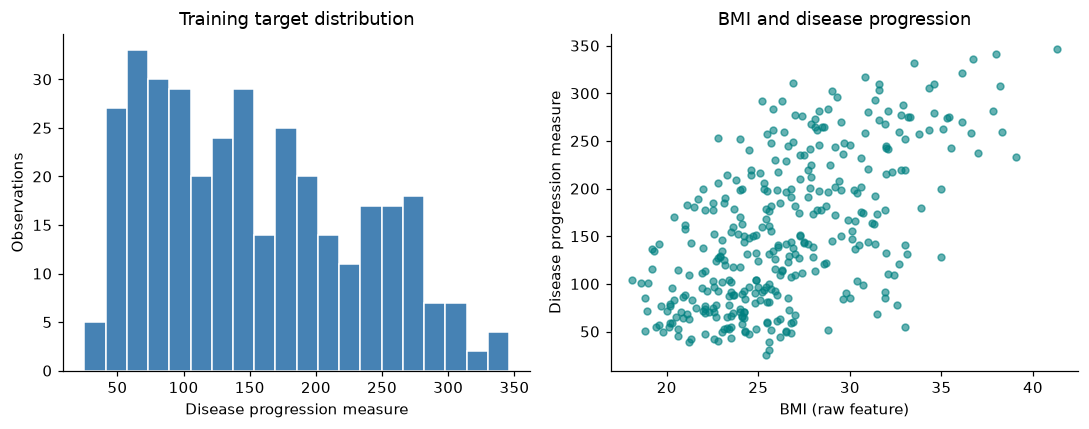

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y_train, bins=20, color="steelblue", edgecolor="white")
axes[0].set(title="Training target distribution",
            xlabel="Disease progression measure", ylabel="Observations")
axes[1].scatter(X_train["bmi"], y_train, alpha=0.6, s=20, color="teal")
axes[1].set(title="BMI and disease progression",
            xlabel="BMI (raw feature)", ylabel="Disease progression measure")
fig.tight_layout()
plt.show()

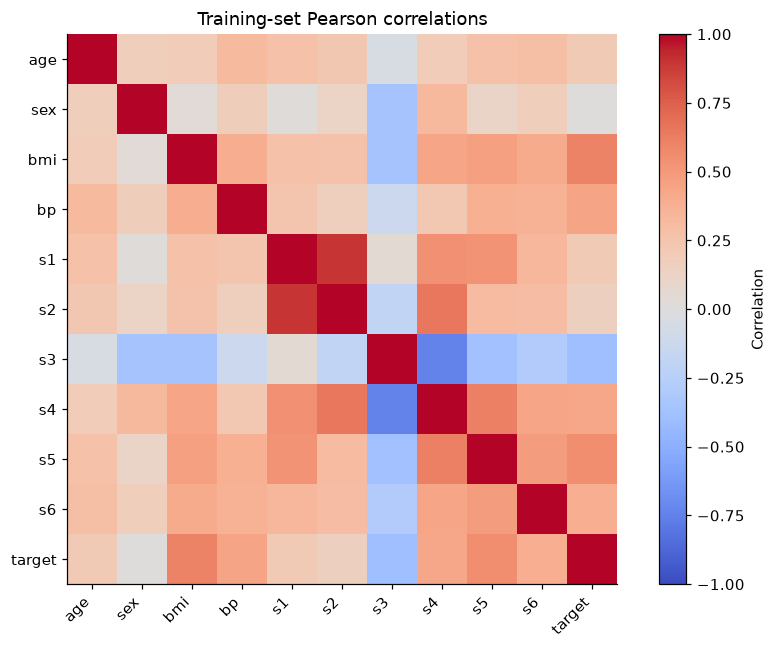

,Correlation with target
bmi,0.605
s5,0.552
bp,0.445
s4,0.425
s6,0.390
s1,0.200
age,0.197
s2,0.155
sex,0.007
s3,-0.384


In [6]:
correlations = train_data.corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlations)), correlations.columns,
              rotation=45, ha="right")
ax.set_yticks(range(len(correlations)), correlations.index)
ax.set_title("Training-set Pearson correlations")
fig.colorbar(image, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

target_correlations = correlations["target"].drop("target")
display(target_correlations.sort_values(ascending=False)
        .round(3).to_frame("Correlation with target"))

## 5. Scale features without data leakage

StandardScaler subtracts the training mean and divides by the training
standard deviation. This makes feature magnitudes comparable, which
helps gradient descent in the Logistic Regression notebook.

Fit the scaler on X_train, then reuse it unchanged on X_test. Fitting
on all observations would let test-set information affect training.
The target is not standardized.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert scaler.n_samples_seen_ == len(X_train)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-12)

scaled_train = pd.DataFrame(X_train_scaled, columns=X.columns,
                            index=X_train.index)
display(pd.DataFrame({
    "Training mean after scaling": scaled_train.mean(),
    "Training SD after scaling": scaled_train.std(ddof=0),
}).round(3))

,Training mean after scaling,Training SD after scaling
age,-0.0,1.0
sex,-0.0,1.0
bmi,-0.0,1.0
bp,-0.0,1.0
s1,-0.0,1.0
s2,0.0,1.0
s3,-0.0,1.0
s4,-0.0,1.0
s5,-0.0,1.0
s6,0.0,1.0


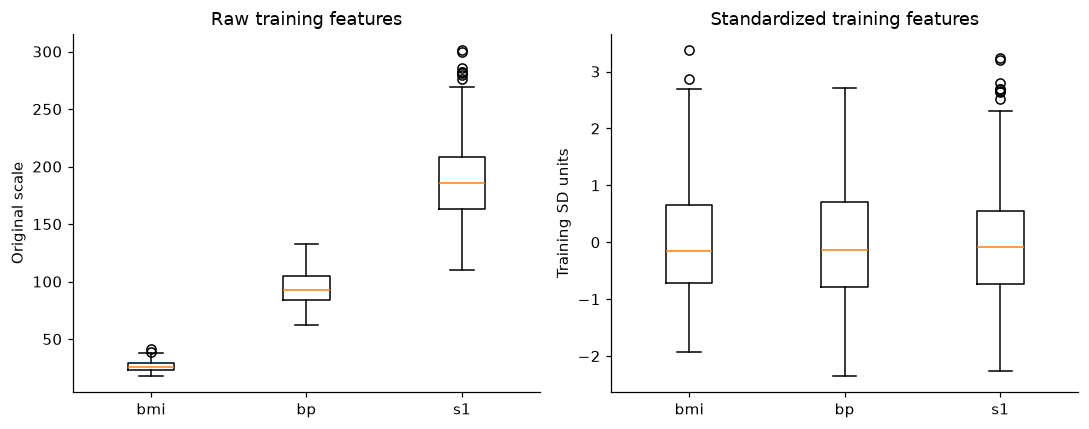

In [8]:
columns = ["bmi", "bp", "s1"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(X_train[columns].to_numpy())
axes[0].set_xticks([1, 2, 3], columns)
axes[0].set(title="Raw training features", ylabel="Original scale")
axes[1].boxplot(scaled_train[columns].to_numpy())
axes[1].set_xticks([1, 2, 3], columns)
axes[1].set(title="Standardized training features", ylabel="Training SD units")
fig.tight_layout()
plt.show()

## Conclusion

The training subset contains 353 observations and no missing values. The strongest positive feature–target correlation in this subset is bmi (0.605). This is an association, not evidence of causation.

Training-only standardization puts features on comparable scales without using the held-out rows. The next two notebooks apply this workflow to installed XinML models.